# 04 · Avaliação, interpretação e conclusões
**Tech Challenge – Fase 2 · Grupo 01 · POSTECH Data Analytics**

Aqui respondemos: **o modelo é bom? Quais características mais pesam? Como usá-lo na prática?**
Tudo é medido no **conjunto de teste** (7.291 clientes com perfis que o modelo nunca viu).

In [1]:
RANDOM_STATE = 42   # semente fixa

import json, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
PROCESSED, RAW = "../data/processed/", "../data/raw/"

NUMERIC = ["CNT_CHILDREN", "CNT_FAM_MEMBERS", "AGE_YEARS", "YEARS_EMPLOYED", "LOG_INCOME", "LOG_INCOME_PER_MEMBER"]
BINARY = ["FLAG_OWN_CAR", "FLAG_OWN_REALTY", "FLAG_WORK_PHONE", "FLAG_PHONE", "FLAG_EMAIL", "IS_MALE", "IS_UNEMPLOYED_OR_RETIRED"]
CATEGORICAL = ["NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE", "NAME_FAMILY_STATUS", "NAME_HOUSING_TYPE", "OCCUPATION_TYPE"]
FEATURES = NUMERIC + BINARY + CATEGORICAL

df = pd.read_csv(PROCESSED + "dataset_model.csv")
modelo = joblib.load(PROCESSED + "modelo_campeao.joblib")
pred = pd.read_csv(PROCESSED + "predicoes_teste.csv")
cortes = json.load(open(PROCESSED + "cortes.json"))["cortes"]
te_idx = np.load(PROCESSED + "idx_teste.npy")
Xte, yte, gte = df.iloc[te_idx][FEATURES], pred.y.values, pred.grupo.values
campeao = modelo["modelo"]
print("Modelo campeão:", campeao, "| clientes no teste:", len(yte), "| % maus:", round(yte.mean() * 100, 2))

Modelo campeão: Random Forest | clientes no teste: 7291 | % maus: 11.77


## 1. Quadro de métricas
Como ler cada coluna (considerando a classe de interesse, o **mau pagador**):
- **Acurácia:** de todos os clientes, quantos o modelo classificou certo. *Enganosa* aqui: recusar ninguém dá 88%.
- **Precisão:** entre os que o modelo **recusou**, quantos eram mesmo maus. Mede os "alarmes verdadeiros".
- **Recall (sensibilidade):** entre os **maus pagadores reais**, quantos o modelo pegou. Mede o quanto de risco foi detectado.
- **F1:** equilíbrio entre precisão e recall em um número só.
- **AUC-ROC:** capacidade de **ordenar** clientes por risco, sem depender do ponto de corte (0,50 = sorteio).

In [2]:
linhas = []
for nome in ["Baseline (Dummy)", "Regressão Logística", "Árvore de Decisão", "Random Forest", "Gradient Boosting (HistGB)"]:
    p, corte = pred[nome].values, cortes[nome]; rec = (p >= corte).astype(int)
    tn, fp, fn, tp = confusion_matrix(yte, rec).ravel()
    linhas.append({"Modelo": nome, "Acurácia": accuracy_score(yte, rec), "Precisão": precision_score(yte, rec, zero_division=0), "Recall": recall_score(yte, rec),
                   "F1": f1_score(yte, rec), "AUC-ROC": roc_auc_score(yte, p), "PR-AUC": average_precision_score(yte, p),
                   "Maus detectados (de 100)": round(100 * tp / (tp + fn)), "Bons recusados (de 100)": round(100 * fp / (fp + tn))})
met = pd.DataFrame(linhas).set_index("Modelo")
display(met.round(3))

,Acurácia,Precisão,Recall,F1,AUC-ROC,PR-AUC,Maus detectados (de 100),Bons recusados (de 100)
Modelo,,,,,,,,
Baseline (Dummy),0.882,0.000,0.000,0.000,0.500,0.118,0,0
Regressão Logística,0.518,0.128,0.534,0.207,0.541,0.137,53,48
Árvore de Decisão,0.551,0.139,0.541,0.221,0.548,0.134,54,45
Random Forest,0.401,0.123,0.670,0.208,0.530,0.136,67,64
Gradient Boosting (HistGB),0.406,0.127,0.685,0.214,0.553,0.141,69,63


**Leitura em linguagem simples:**
- A **acurácia dos modelos (40% a 55%) é menor que a da referência (88%)**. Isso não é erro: a referência "acerta" só porque aprova todos, e nunca detecta um mau pagador.
  Os modelos aceitam errar em bons clientes para tentar pegar os maus.
- **Quanto custa pegar os maus?** Pegue o Random Forest: ele detecta cerca de **67 de cada 100 maus pagadores**, mas para isso **recusa cerca de 64 de cada 100 bons**.
  Em outras palavras, a maioria dos recusados seria bom cliente. A **precisão é de ~12%, praticamente a mesma taxa geral de maus (11,8%)**: recusar pelo modelo não é muito melhor do que recusar ao acaso.
- A **AUC-ROC (0,53 a 0,55)** confirma: o modelo ordena os clientes só um pouco melhor que um sorteio.

**Métricas priorizadas:** AUC-ROC, PR-AUC e recall dos maus. Acurácia não serve como critério por causa do desbalanceamento (88% × 12%), e um falso negativo (aprovar um mau pagador) costuma custar mais que um falso positivo (recusar um bom).

## 2. Curvas ROC e Precisão × Recall

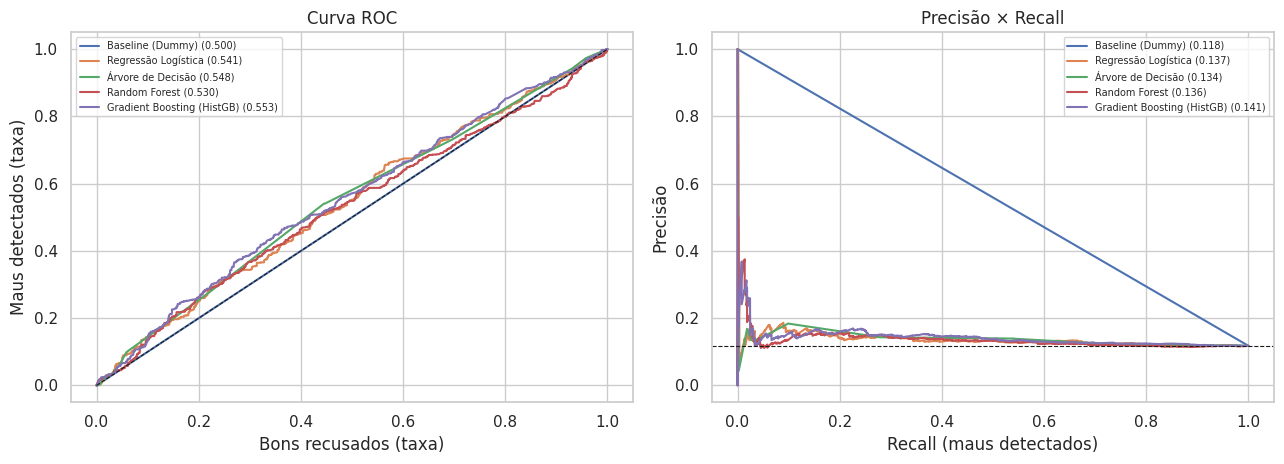

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for nome in met.index:
    p = pred[nome].values
    fpr, tpr, _ = roc_curve(yte, p); axes[0].plot(fpr, tpr, label=f"{nome} ({roc_auc_score(yte, p):.3f})")
    pr, rc, _ = precision_recall_curve(yte, p); axes[1].plot(rc, pr, label=f"{nome} ({average_precision_score(yte, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=.8); axes[0].set(title="Curva ROC", xlabel="Bons recusados (taxa)", ylabel="Maus detectados (taxa)")
axes[1].axhline(yte.mean(), color="k", ls="--", lw=.8); axes[1].set(title="Precisão × Recall", xlabel="Recall (maus detectados)", ylabel="Precisão")
axes[0].legend(fontsize=7); axes[1].legend(fontsize=7); plt.tight_layout(); plt.show()

**Leitura:** na curva ROC, um modelo perfeito seguiria o canto superior esquerdo; um sorteio, a diagonal tracejada. **Todas as curvas ficam coladas na diagonal.**
Na curva Precisão × Recall, a linha tracejada é a taxa geral de maus (11,8%): as curvas dos modelos ficam pouco acima dela, ou seja, a precisão só melhora um pouco quando se aceita detectar menos maus.

## 3. Matriz de confusão do modelo campeão

Aprovou bons: 2347 | Recusou bons (perda de negócio): 4086 | Aprovou maus (risco): 283 | Recusou maus (acerto): 575


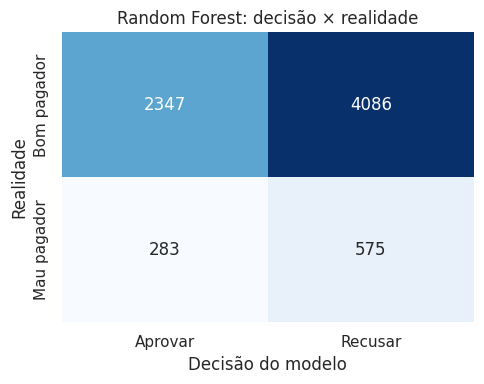

In [4]:
corte = cortes[campeao]; rec = (pred[campeao].values >= corte).astype(int)
cm = confusion_matrix(yte, rec)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, xticklabels=["Aprovar", "Recusar"], yticklabels=["Bom pagador", "Mau pagador"])
ax.set(title=f"{campeao}: decisão × realidade", xlabel="Decisão do modelo", ylabel="Realidade"); plt.tight_layout(); plt.show()
tn, fp, fn, tp = cm.ravel()
print(f"Aprovou bons: {tn} | Recusou bons (perda de negócio): {fp} | Aprovou maus (risco): {fn} | Recusou maus (acerto): {tp}")

**Leitura:** a diagonal principal (Bom×Aprovar e Mau×Recusar) são os acertos. As outras duas casas são os erros:
**recusar um bom cliente** (perde-se receita) e **aprovar um mau pagador** (perde-se dinheiro com inadimplência). O modelo reduz o segundo erro à custa de aumentar muito o primeiro.

## 4. Intervalo de confiança da nota
A nota de um único teste tem incerteza. Repetimos o cálculo 300 vezes sorteando perfis com reposição (bootstrap) para ver a faixa plausível.

In [5]:
rng = np.random.default_rng(RANDOM_STATE)
d = pd.DataFrame({"y": yte, "p": pred[campeao].values, "g": gte}); idx_by_g = d.groupby("g").indices; keys = np.array(list(idx_by_g))
aucs = []
for _ in range(300):
    ii = np.concatenate([idx_by_g[k] for k in rng.choice(keys, size=len(keys), replace=True)])
    if d.y.values[ii].min() != d.y.values[ii].max(): aucs.append(roc_auc_score(d.y.values[ii], d.p.values[ii]))
lo, hi = np.percentile(aucs, [2.5, 97.5])
print(f"AUC-ROC do {campeao}: {roc_auc_score(yte, d.p):.3f} | intervalo de 95%: [{lo:.3f} ; {hi:.3f}]")

AUC-ROC do Random Forest: 0.530 | intervalo de 95%: [0.496 ; 0.565]


**Leitura:** com 95% de confiança, a nota verdadeira está entre ~0,50 e ~0,57. **O intervalo inclui 0,50 (sorteio)**: não dá para afirmar com segurança que o modelo é melhor que o acaso.
Como as notas dos quatro algoritmos são parecidas, também não dá para dizer que um é realmente superior aos demais.

## 5. Poder de triagem: o risco cresce com a nota?
Ordenamos os clientes do teste pela nota de risco, dividimos em 10 grupos de tamanho igual (decis) e olhamos a taxa real de maus em cada um.

,% maus,clientes,lift
decil,,,
1,13.8,730,1.18
2,9.7,729,0.83
3,10.0,729,0.85
4,9.9,729,0.84
5,9.9,729,0.84
6,11.0,729,0.93
7,11.4,729,0.97
8,12.2,729,1.04
9,14.8,729,1.26


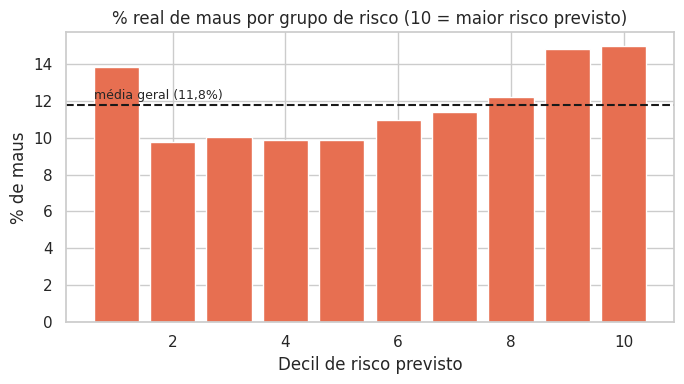

In [6]:
d["decil"] = pd.qcut(d.p.rank(method="first"), 10, labels=False) + 1
dec = d.groupby("decil").y.agg(taxa_maus="mean", clientes="size"); dec["lift"] = dec.taxa_maus / yte.mean()
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(dec.index, dec.taxa_maus * 100, color="#e76f51"); ax.axhline(yte.mean() * 100, color="k", ls="--"); ax.text(0.6, yte.mean() * 100 + 0.3, "média geral (11,8%)", fontsize=9)
ax.set(title="% real de maus por grupo de risco (10 = maior risco previsto)", xlabel="Decil de risco previsto", ylabel="% de maus"); plt.tight_layout(); plt.show()
display((dec.assign(taxa_maus=(dec.taxa_maus * 100).round(1)).rename(columns={"taxa_maus": "% maus"})).round(2))

**Leitura:** em um bom modelo, as barras cresceriam de forma clara da esquerda para a direita. Aqui crescem **pouco e de forma irregular**:
os dois grupos de maior risco (decis 9 e 10) têm cerca de **15% de maus contra 11,8% da média** (o risco é ~1,3 vez maior).
Existe algum sinal, mas fraco. Serve para **priorizar** casos para análise humana, não para decidir sozinho.

## 6. O que mais pesa na decisão?
Medimos a **importância por permutação**: embaralhamos uma característica por vez e vemos quanto a nota do modelo piora. Quanto maior a queda, mais o modelo dependia daquela informação.

,variável,queda_na_nota,desvio
2,Idade,0.0172,0.0054
7,Imóvel próprio,0.0080,0.0009
6,Carro próprio,0.0075,0.0012
3,Tempo de emprego,0.0059,0.0047
11,Gênero (masculino),0.0027,0.0012
0,Nº de filhos,0.0023,0.0008
1,Pessoas na família,0.0017,0.0013
8,Telefone comercial,0.0007,0.0004
12,Sem emprego/aposentado,-0.0001,0.0009
4,Renda,-0.0005,0.0014


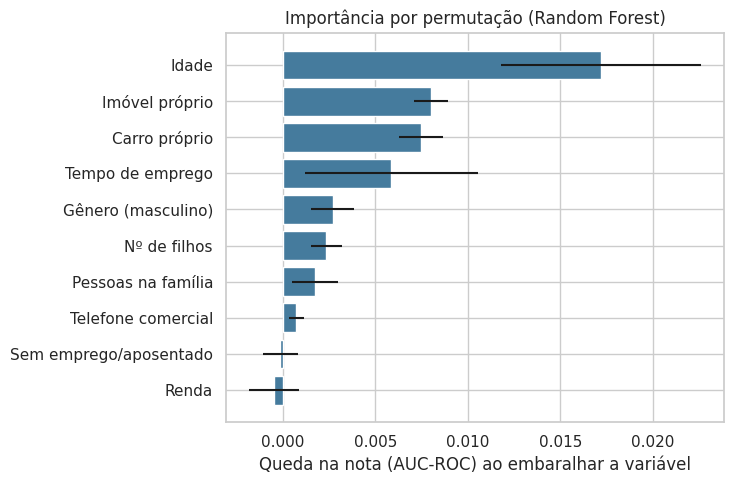

In [7]:
pi = permutation_importance(modelo["pipeline"], Xte, yte, scoring="roc_auc", n_repeats=10, random_state=RANDOM_STATE, n_jobs=1)
imp = pd.DataFrame({"variavel": FEATURES, "queda_na_nota": pi.importances_mean, "desvio": pi.importances_std}).sort_values("queda_na_nota", ascending=False)
nomes = {"AGE_YEARS": "Idade", "FLAG_OWN_REALTY": "Imóvel próprio", "FLAG_OWN_CAR": "Carro próprio", "YEARS_EMPLOYED": "Tempo de emprego", "IS_MALE": "Gênero (masculino)",
         "CNT_CHILDREN": "Nº de filhos", "CNT_FAM_MEMBERS": "Pessoas na família", "FLAG_WORK_PHONE": "Telefone comercial", "IS_UNEMPLOYED_OR_RETIRED": "Sem emprego/aposentado",
         "LOG_INCOME": "Renda", "LOG_INCOME_PER_MEMBER": "Renda por pessoa da família", "FLAG_PHONE": "Telefone residencial", "FLAG_EMAIL": "E-mail informado",
         "NAME_INCOME_TYPE": "Tipo de renda", "NAME_EDUCATION_TYPE": "Escolaridade", "NAME_FAMILY_STATUS": "Estado civil", "NAME_HOUSING_TYPE": "Tipo de moradia", "OCCUPATION_TYPE": "Ocupação"}
imp["variável"] = imp.variavel.map(nomes)
top = imp.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 5)); ax.barh(top["variável"], top.queda_na_nota, xerr=top.desvio, color="#457b9d")
ax.set(title=f"Importância por permutação ({campeao})", xlabel="Queda na nota (AUC-ROC) ao embaralhar a variável"); plt.tight_layout(); plt.show()
display(imp[["variável", "queda_na_nota", "desvio"]].round(4).head(10))

**Leitura (o que significa cada variável importante):**
- **Idade (a mais importante):** clientes mais jovens têm mais atrasos (13,4% de maus entre 20 e 30 anos contra 10,6% entre 60 e 70). Pode refletir menos estabilidade financeira no início da vida.
- **Imóvel próprio:** quem tem imóvel atrasa menos (11,1% × 13,1%). O imóvel funciona como sinal de patrimônio e de estabilidade.
- **Carro próprio:** mesma direção, efeito menor.
- **Tempo de emprego:** contribui um pouco, mas sem um padrão simples (não é "quanto mais tempo, menos risco").
- **Gênero:** aparece com pequeno peso (12,7% de maus entre homens, 11,3% entre mulheres). Usar esse tipo de variável em decisão de crédito exige cuidado ético e legal.
- **Renda:** pesa quase zero. Na prática, **ganhar mais não significou pagar melhor** nesta base.

Os pesos são **pequenos** (a maior queda é de ~0,017 pontos de nota): nenhuma característica sozinha define o risco.

## 7. E o custo? Vale a pena usar o modelo para recusar?
Se aprovar um mau pagador custa **R vezes** mais que recusar um bom (R = 1, 2, 3, 5, 8, 10), comparamos o custo total do modelo com as duas estratégias simples: aprovar todos ou recusar todos.

In [8]:
p, rec = pred[campeao].values, (pred[campeao].values >= cortes[campeao])
fn = int(((~rec) & (yte == 1)).sum()); fp = int((rec & (yte == 0)).sum())
tab = []
for r in [1, 2, 3, 5, 8, 10]:
    modelo_c, aprova_todos, recusa_todos = r * fn + fp, r * int((yte == 1).sum()), int((yte == 0).sum())
    melhor_simples = min(aprova_todos, recusa_todos)
    tab.append({"custo de aprovar um mau (R)": r, "custo do modelo": modelo_c, "custo se aprovar todos": aprova_todos, "custo se recusar todos": recusa_todos,
                "economia vs melhor estratégia simples (%)": round(100 * (melhor_simples - modelo_c) / melhor_simples, 1)})
display(pd.DataFrame(tab))

,custo de aprovar um mau (R),custo do modelo,custo se aprovar todos,custo se recusar todos,economia vs melhor estratégia simples (%)
0,1,4369,858,6433,-409.2
1,2,4652,1716,6433,-171.1
2,3,4935,2574,6433,-91.7
3,5,5501,4290,6433,-28.2
4,8,6350,6864,6433,1.3
5,10,6916,8580,6433,-7.5


**Leitura:** a economia é **negativa** para R de 1 a 5 (o modelo custa mais que simplesmente aprovar todos) e fica em torno de zero só quando um mau pagador custa ~8 vezes mais que um bom cliente recusado.
Conclusão: **com estes dados, o modelo não justifica automatizar a decisão**; mesmo com custos reais, o ganho seria pequeno.

## 8. Teste de robustez: o perigo dos perfis repetidos
Repetimos o treino de um Random Forest com dois tipos de divisão: **aleatória** (perfis repetidos podem ficar nos dois lados) e **agrupada** (a que usamos).
Também testamos outras definições de "mau pagador".

In [9]:
def rf():
    prep = ColumnTransformer([("num", StandardScaler(), NUMERIC), ("bin", "passthrough", BINARY),
                              ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=30), CATEGORICAL)])
    return Pipeline([("prep", prep), ("clf", RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE))])

def avaliar(y, agrupado):
    X, g = df[FEATURES], df.PROFILE_GROUP.values
    if agrupado: tr, te = next(StratifiedGroupKFold(5, shuffle=True, random_state=RANDOM_STATE).split(X, y, g))
    else:        tr, te = next(StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE).split(X, y))
    p = rf().fit(X.iloc[tr], y[tr]).predict_proba(X.iloc[te])[:, 1]
    visto = df.iloc[te].PROFILE_GROUP.isin(set(df.iloc[tr].PROFILE_GROUP)).mean()
    return {"AUC-ROC": round(roc_auc_score(y[te], p), 3), "PR-AUC": round(average_precision_score(y[te], p), 3), "% do teste com perfil já visto no treino": round(100 * visto, 1)}

y30 = df.TARGET.values
vaz = pd.DataFrame({"divisão aleatória (incorreta)": avaliar(y30, False), "divisão agrupada (adotada)": avaliar(y30, True)}).T
display(vaz)

,AUC-ROC,PR-AUC,% do teste com perfil já visto no treino
divisão aleatória (incorreta),0.760,0.371,89.4
divisão agrupada (adotada),0.505,0.122,0.0


**Leitura:** com a divisão aleatória o modelo parece muito melhor (**AUC 0,76**), mas **89% do teste são perfis que ele já viu no treino**: ele só reconhece rostos conhecidos.
Com a divisão correta, a nota real é **~0,51**. É como dar a prova com as respostas para a turma: a nota sobe, mas ninguém aprendeu.
**Por que isso importa:** quem usar esta base sem esse cuidado vai apresentar um modelo "ótimo" que, na vida real, não funcionaria.

In [10]:
cred = pd.read_csv(RAW + "credit_record.csv")
linhas = []
for t, nome in [(1, "atraso de 30 dias ou mais (adotada)"), (2, "atraso de 60 dias ou mais"), (3, "atraso de 90 dias ou mais")]:
    alvo = cred["STATUS"].isin([str(s) for s in range(t, 6)]).groupby(cred["ID"]).max().astype(int)
    y = df.ID.map(alvo).values
    linhas.append({"definição de mau pagador": nome, "% de maus": round(100 * y.mean(), 2), **{k: v for k, v in avaliar(y, True).items() if k != "% do teste com perfil já visto no treino"}})
display(pd.DataFrame(linhas).set_index("definição de mau pagador"))

,% de maus,AUC-ROC,PR-AUC
definição de mau pagador,,,
atraso de 30 dias ou mais (adotada),11.77,0.505,0.122
atraso de 60 dias ou mais,1.69,0.563,0.047
atraso de 90 dias ou mais,0.83,0.625,0.087


**Leitura:** atrasos mais graves (60 e 90 dias) são um pouco mais "previsíveis" (AUC 0,56 e 0,63), mas com apenas 1,7% e 0,8% de maus pagadores, ou seja, **muito poucos casos**: o resultado é instável.
Mantivemos 30 dias por oferecer mais exemplos para o modelo aprender.

## 9. Conclusões, em linguagem de negócio

**Resposta curta:** com os dados cadastrais disponíveis, **não é possível prever com confiança quem será mau pagador**. O melhor que conseguimos foi um modelo que ordena os clientes só um pouco melhor que um sorteio.

**O que isso significa na prática**
1. **O modelo não deve decidir sozinho.** Para detectar ~2 em cada 3 maus pagadores ele recusaria ~2 em cada 3 bons clientes, e a precisão dos recusados (~12%) é quase igual à taxa geral de maus (11,8%).
2. **Pode servir como apoio à triagem:** os 20% de clientes com maior risco previsto têm cerca de 15% de maus pagadores, contra 11,8% da média. Isso ajuda a *priorizar* a análise humana, não a *substituir* a análise.
3. **Quem tem mais risco (diferenças pequenas):** clientes mais jovens, sem imóvel próprio (e, em menor grau, sem carro), e certos perfis como ensino superior incompleto ou moradia alugada. Quem tem **renda alta não é necessariamente melhor pagador**.
4. **Nenhuma característica isolada define o risco.** O risco de atraso depende muito mais do **comportamento de pagamento** do que do perfil cadastral.
5. **Cuidado com resultados "bons demais":** com divisão aleatória o modelo chegaria a AUC 0,76, mas é ilusório, causado por perfis repetidos entre treino e teste.

**Glossário rápido das variáveis**
| Variável | O que é | Efeito observado |
|---|---|---|
| Idade | Idade do solicitante | Mais jovem → um pouco mais de risco |
| Imóvel / carro próprio | Posse de bens | Quem tem → um pouco menos de risco |
| Tempo de emprego | Anos no emprego atual (0 se não trabalha) | Efeito pequeno e sem padrão claro |
| Renda | Renda anual (usamos o log) | Quase nenhum efeito |
| Ocupação, escolaridade, estado civil, moradia | Perfil do solicitante | Diferenças de 1 a 3 pontos percentuais |
| Gênero | Masculino/feminino | Pequena diferença; uso exige cuidado ético e legal |

**Limitações e próximos passos**
- **Falta informação:** incluir histórico em bureaus de crédito, movimentação financeira e relacionamento com o banco é o caminho mais promissor.
- **O rótulo foi construído por nós** (atraso ≥ 30 dias) e deve ser alinhado à política de risco real da instituição.
- **Só há resposta para quem já recebeu crédito** (viés de seleção): o modelo não conhece o comportamento de quem foi recusado.
- **Custos reais** de aprovar um mau pagador e de recusar um bom devem substituir as razões de exemplo.
- **Ética e regulação:** avaliar o uso de gênero e idade e monitorar o modelo ao longo do tempo antes de qualquer uso em produção.